## Вводные по кейсу

Бизнес просит просто оценить текущее состояние — без глубокой сегментации и оценки сложных метрик.

# Описание данных

## Таблица `Users`

| Поле              | Описание                                       |
|-------------------|------------------------------------------------|
| `user_id`         | Уникальный идентификатор пользователя.         |
| `registration_date` | Дата регистрации пользователя.                |
| `age`             | Возраст пользователя.                          |
| `gender`          | Пол.                                |
| `region`          | Регион.                                        |
| `acq_channel`     | Канал привлечения.                             |
| `buyer_segment`   | Сегмент покупателя.                            |
| `cohort_week`     | Неделя привлечения.|
| `cohort_month`    | Месяц привлечения. |

---

## Таблица `Events`

| Поле          | Описание                                                                 |
|---------------|--------------------------------------------------------------------------|
| `event_id`    | Уникальный идентификатор события.                                        |
| `user_id`     | Идентификатор пользователя.                                              |
| `event_date`  | Дата события.                                                            |
| `event_type`  | Тип события.   |
| `os`          | Операционная система.               |
| `device`      | Тип устройства.                                |
| `product_name`| Наименование товара, к которому относится событие (если применимо).      |
| `event_week`  | Неделя события.                                          |
| `event_month` | Месяц события .                                           |

---

## Таблица `Orders`

| Поле          | Описание                                                                 |
|---------------|--------------------------------------------------------------------------|
| `order_id`    | Уникальный идентификатор заказа.                                         |
| `user_id`     | Идентификатор пользователя, который сделал заказ |
| `order_date`  | Дата и время оформления заказа.                                          |
| `product_name`| Наименование товара.                                                     |
| `quantity`    | Количество единиц товара в заказе.                                       |
| `unit_price`  | Цена за одну единицу товара.                                             |
| `total_price` | Итоговая сумма заказа.                                                   |
| `category_name` | Наименование категории товара.                                         |
| `order_week`  | Неделя заказа.                                           |
| `order_month` | Месяц заказа.                                            |


## Таблица `Campaign_costs`

| Поле         | Описание                                                                 |
|--------------|--------------------------------------------------------------------------|
| `acq_channel`| Канал привлечения.  |
| `spend_month`| Месяц, в который был потрачен бюджет (отражает период, в котором были привлечены пользователи)                      |
| `budget`     | Маркетинговый бюджет (в денежном выражении), потраченный на данный канал в указанном месяце.                           |



## Описание событий

| Событие             | Описание                                                                                  |
|---------------------|-------------------------------------------------------------------------------------------|
| `page_view`         | Открытие любой страницы сайта или приложения пользователем.                                |
| `product_view`      | Просмотр страницы конкретного товара.                                                     |
| `product_click`     | Клик по товару (например, из списка товаров или на баннере).                              |
| `add_to_cart`       | Добавление товара в корзину.                                                              |
| `remove_from_cart`  | Удаление товара из корзины.                                                               |
| `search`            | Выполнение поиска по сайту или приложению.                                                |
| `filter_apply`      | Применение фильтра (например, по цене, бренду, категории).                                |
| `checkout_start`    | Начало оформления заказа (переход к оформлению корзины).                                  |
| `checkout_complete` | Завершение оформления заказа (не гарантирует покупку, покупка зависит от факта оплаты).                                          |
| `user_login`        | Вход пользователя в личный кабинет или аккаунт.                                           |
| `user_logout`       | Выход пользователя из аккаунта.                                                           |
| `wishlist_add`      | Добавление товара в список желаемого (wishlist).                                          |
| `category_view`     | Просмотр страницы категории товаров.                                                      |
| `banner_click`      | Клик по рекламному баннеру на сайте или в приложении.                                     |
| `promo_view`        | Просмотр промо-акции или специального предложения.                                        |


## Выручка маркетплейса = 5% от total_price

# Блок кода и расчета метрик

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import numpy as np
from scipy import stats
from scipy.stats import ttest_ind
from scipy.stats import mannwhitneyu, bootstrap
from statsmodels.stats.proportion import proportions_ztest


In [2]:
pa_marketplace_orders = pd.read_csv('/datasets/pa_marketplace_orders.csv', parse_dates=['order_date'])
pa_marketplace_campaign_costs = pd.read_csv('/datasets/pa_marketplace_campaign_costs.csv')
pa_marketplace_users = pd.read_csv('datasets/pa_marketplace_users.csv', parse_dates=['registration_date'])
pa_marketplace_events = pd.read_csv('/datasets/pa_marketplace_events.csv', parse_dates=['event_date'])

In [3]:
pa_marketplace_orders.info()
display(pa_marketplace_orders.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31357 entries, 0 to 31356
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       31357 non-null  int64         
 1   user_id        31357 non-null  int64         
 2   order_date     31357 non-null  datetime64[ns]
 3   product_name   31357 non-null  object        
 4   quantity       31357 non-null  int64         
 5   unit_price     31357 non-null  float64       
 6   total_price    31357 non-null  float64       
 7   category_name  31357 non-null  object        
 8   order_week     31357 non-null  object        
 9   order_month    31357 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(3), object(4)
memory usage: 2.4+ MB


,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
0,1,3,2024-01-19 01:52:52,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
1,2,3,2024-01-19 01:52:52,Молоток слесарный,1,11340.38,11340.38,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
2,3,3,2024-01-19 01:52:52,Секатор садовый,2,10892.09,21784.18,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
3,4,3,2024-01-25 13:59:38,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-22,2024-01-01
4,5,3,2024-01-25 13:59:38,Чай черный,1,2099.59,2099.59,Продукты питания,2024-01-22,2024-01-01


In [4]:
pa_marketplace_campaign_costs = pa_marketplace_campaign_costs.drop(columns=['Unnamed: 0'])
pa_marketplace_campaign_costs.info()
display(pa_marketplace_campaign_costs.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88 entries, 0 to 87
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   acq_channel  88 non-null     object 
 1   spend_month  88 non-null     object 
 2   budget       88 non-null     float64
dtypes: float64(1), object(2)
memory usage: 2.2+ KB


,acq_channel,spend_month,budget
0,Affiliate,2024-01-01,179343.3875
1,Affiliate,2024-02-01,175488.4875
2,Affiliate,2024-03-01,164543.4750
3,Affiliate,2024-04-01,186869.9750
4,Affiliate,2024-05-01,166443.7750


In [5]:
pa_marketplace_users.info()
display(pa_marketplace_users.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44151 entries, 0 to 44150
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            44151 non-null  int64         
 1   registration_date  44151 non-null  datetime64[ns]
 2   age                44151 non-null  int64         
 3   gender             44151 non-null  object        
 4   region             44151 non-null  object        
 5   acq_channel        44151 non-null  object        
 6   buyer_segment      44151 non-null  object        
 7   cohort_week        44151 non-null  object        
 8   cohort_month       44151 non-null  object        
dtypes: datetime64[ns](1), int64(2), object(6)
memory usage: 3.0+ MB


,user_id,registration_date,age,gender,region,acq_channel,buyer_segment,cohort_week,cohort_month
0,1,2024-01-01 00:47:00,35,M,Москва,Google Ads,regular,2024-01-01,2024-01-01
1,2,2024-01-01 19:01:00,53,M,Москва,Email Marketing,rare,2024-01-01,2024-01-01
2,3,2024-01-01 04:13:00,66,F,Санкт-Петербург,Google Ads,regular,2024-01-01,2024-01-01
3,4,2024-01-01 17:18:00,58,M,Краснодар,Affiliate,one_time,2024-01-01,2024-01-01
4,5,2024-01-01 08:29:00,58,F,Другие регионы,Google Ads,regular,2024-01-01,2024-01-01


In [6]:
pa_marketplace_events.info()
display(pa_marketplace_events.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 785859 entries, 0 to 785858
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   event_id      785859 non-null  int64         
 1   user_id       785859 non-null  int64         
 2   event_date    785859 non-null  datetime64[ns]
 3   event_type    785859 non-null  object        
 4   os            785859 non-null  object        
 5   device        785859 non-null  object        
 6   product_name  385740 non-null  object        
 7   event_week    785859 non-null  object        
 8   event_month   785859 non-null  object        
dtypes: datetime64[ns](1), int64(2), object(6)
memory usage: 54.0+ MB


,event_id,user_id,event_date,event_type,os,device,product_name,event_week,event_month
0,3132,100,2024-01-01,page_view,iOS,mobile,NaN,2024-01-01,2024-01-01
1,3133,100,2024-01-01,product_view,iOS,mobile,Шорты для тренировок,2024-01-01,2024-01-01
2,3134,100,2024-01-01,product_click,iOS,mobile,Куртка детская,2024-01-01,2024-01-01
3,3135,100,2024-01-01,add_to_cart,iOS,mobile,Балетки классические,2024-01-01,2024-01-01
4,3136,100,2024-01-01,checkout_start,iOS,mobile,NaN,2024-01-01,2024-01-01


In [7]:
num_duplicates = pa_marketplace_orders.duplicated().sum()
print(f"Всего дублирующих строк в orders: {num_duplicates}")
num_duplicates = pa_marketplace_users.duplicated().sum()
print(f"Всего дублирующих строк в users: {num_duplicates}")
num_duplicates = pa_marketplace_events.duplicated().sum()
print(f"Всего дублирующих строк в events: {num_duplicates}")

Всего дублирующих строк в orders: 0
Всего дублирующих строк в users: 0
Всего дублирующих строк в events: 0


Явных дубликатов не обнаружено.

In [8]:
cols = ['user_id', 'order_date', 'product_name', 'total_price']
dup_mask = pa_marketplace_orders.duplicated(subset=cols, keep=False)
duplicates = pa_marketplace_orders[dup_mask].sort_values(by=cols)
print(f"Количество дубликатов: {dup_mask.sum()}, {dup_mask.sum() / len(pa_marketplace_orders):.2%} от общего числа")
display(duplicates.head(6))

Количество дубликатов: 537, 1.71% от общего числа


,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
232,233,203,2024-02-07 22:19:44,Тетрадь общая,1,2829.81,2829.81,Книги и канцтовары,2024-02-05,2024-02-01
233,234,203,2024-02-07 22:19:44,Тетрадь общая,1,2829.81,2829.81,Книги и канцтовары,2024-02-05,2024-02-01
459,460,362,2024-01-26 02:59:13,Свечи зажигания,3,7696.64,23089.92,Автотовары,2024-01-22,2024-01-01
460,461,362,2024-01-26 02:59:13,Свечи зажигания,3,7696.64,23089.92,Автотовары,2024-01-22,2024-01-01
562,563,420,2024-01-13 19:39:50,Чайник электрический,3,6254.47,18763.41,Товары для кухни,2024-01-08,2024-01-01
563,564,420,2024-01-13 19:39:50,Чайник электрический,3,6254.47,18763.41,Товары для кухни,2024-01-08,2024-01-01


Укзанные строки являются неявными дубликатами, их можно удалить.

In [9]:
pa_marketplace_orders = pa_marketplace_orders.drop_duplicates(subset=cols, keep='first')
remaining_dup_count = pa_marketplace_orders.duplicated(subset=cols).sum()
print(f"Осталось дубликатов: {remaining_dup_count}")

Осталось дубликатов: 0


### 2. Обзор ключевых метрик

Выручка бизнеса — 5% комиссии от стоимости любой продажи.

In [10]:
users_by_month = pa_marketplace_events.groupby('event_month')['user_id'].nunique().reset_index().rename(columns={'event_month': 'month','user_id': 'users'})
arpu_by_month = pa_marketplace_orders.groupby('order_month').agg(
    total_amount = ('total_price', 'sum'),
    paying_users = ('user_id', 'nunique')).reset_index().rename(columns={'order_month': 'month'})

arpu_by_month = arpu_by_month.merge(users_by_month, on='month', how='inner')

arpu_by_month['paying_share'] = round(arpu_by_month['paying_users'] / arpu_by_month['users'], 2)
arpu_by_month['revenue'] = arpu_by_month['total_amount'] * 0.05
arpu_by_month['arpu'] =  arpu_by_month['revenue']  / arpu_by_month['users']
arpu_by_month['arppu'] =  arpu_by_month['revenue']  / arpu_by_month['paying_users']
display(arpu_by_month)

,month,total_amount,paying_users,users,paying_share,revenue,arpu,arppu
0,2024-01-01,12853222.23,454,1149,0.40,6.426611e+05,559.322116,1415.553109
1,2024-02-01,25820076.52,839,2162,0.39,1.291004e+06,597.134055,1538.741151
2,2024-03-01,38226803.72,1165,2844,0.41,1.911340e+06,672.060544,1640.635353
3,2024-04-01,42406554.11,1324,3059,0.43,2.120328e+06,693.144068,1601.455971
4,2024-05-01,49149201.52,1404,3310,0.42,2.457460e+06,742.435068,1750.327689
5,2024-06-01,41875283.43,1230,3174,0.39,2.093764e+06,659.661050,1702.247294
6,2024-07-01,48548210.99,1385,3481,0.40,2.427411e+06,697.331385,1752.642996
7,2024-08-01,48975196.68,1385,3861,0.36,2.448760e+06,634.229431,1768.057642
8,2024-09-01,38444597.28,1163,3744,0.31,1.922230e+06,513.416096,1652.820175
9,2024-10-01,34170797.40,999,3581,0.28,1.708540e+06,477.112502,1710.250120


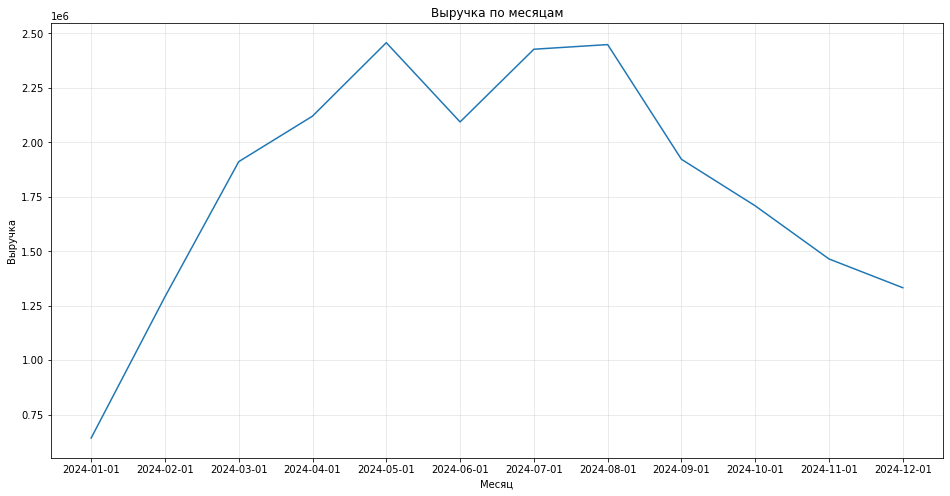

In [11]:
plt.figure(figsize=(16, 8))
plt.plot(arpu_by_month['month'], arpu_by_month['revenue'])
plt.xlabel("Месяц")
plt.ylabel("Выручка")
plt.title('Выручка по месяцам')
plt.grid(True, alpha=0.3)
plt.show()

Выручка росла до мая, в мае немного просела, в июне вернулась к апрельским значениям. В августе началось падение выручки.

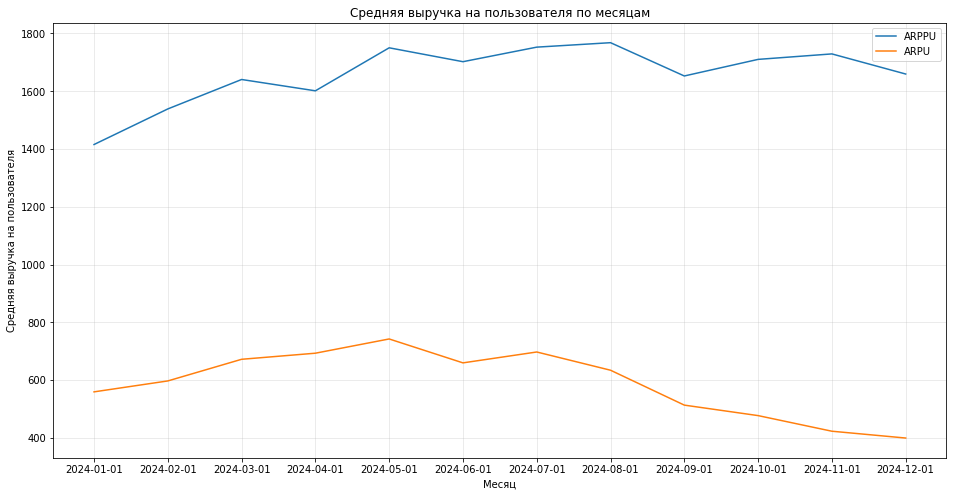

In [12]:
plt.figure(figsize=(16, 8))
plt.plot(arpu_by_month['month'], arpu_by_month['arppu'], label='ARPPU')
plt.plot(arpu_by_month['month'], arpu_by_month['arpu'], label='ARPU')
plt.xlabel("Месяц")
plt.ylabel("Средняя выручка на пользователя")
plt.title("Средняя выручка на пользователя по месяцам")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Средняя выручка на платящих пользователей остаётся стабильной. Средняя выручка на пользователя падает с июня за счёт уменьшения доли платящих пользователей.

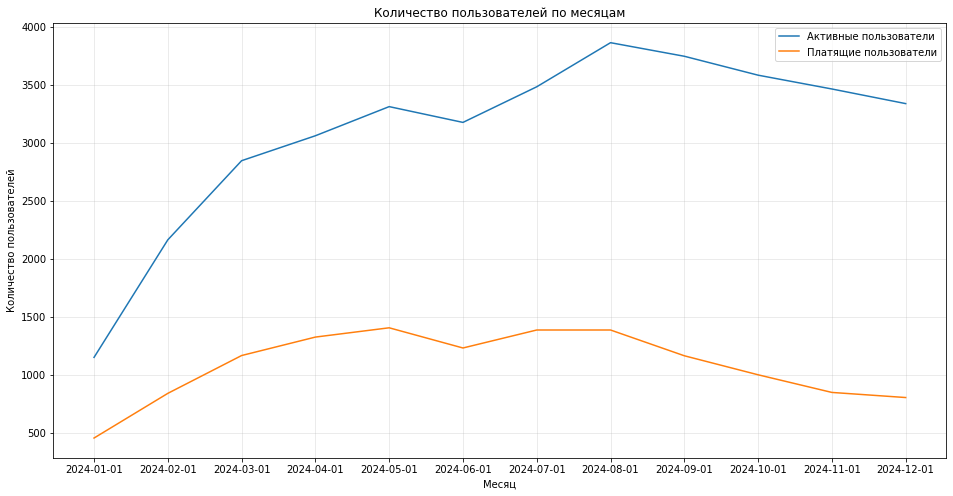

In [13]:
plt.figure(figsize=(16, 8))
plt.plot(arpu_by_month['month'], arpu_by_month['users'], label='Активные пользователи')
plt.plot(arpu_by_month['month'], arpu_by_month['paying_users'], label='Платящие пользователи')
plt.xlabel("Месяц")
plt.ylabel("Количество пользователей")
plt.title("Количество пользователей по месяцам")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

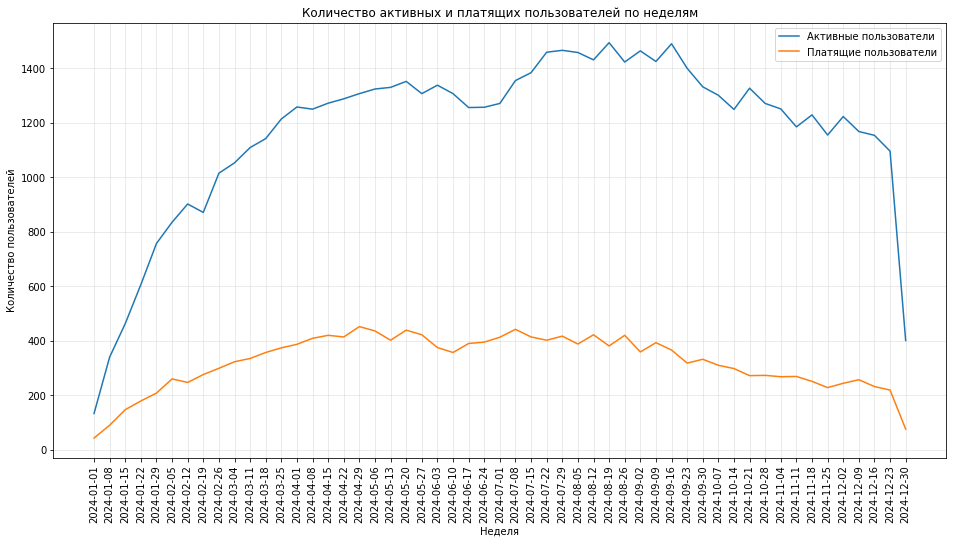

In [14]:
users_by_week = pa_marketplace_events.groupby('event_week')['user_id'].nunique().reset_index()
paying_users_by_week = pa_marketplace_orders.groupby('order_week')['user_id'].nunique().reset_index()
plt.figure(figsize=(16, 8))
plt.plot(users_by_week['event_week'], users_by_week['user_id'], label='Активные пользователи')
plt.plot(paying_users_by_week['order_week'], paying_users_by_week['user_id'], label='Платящие пользователи')

plt.xlabel("Неделя")
plt.ylabel("Количество пользователей")
plt.title("Количество активных и платящих пользователей по неделям")
plt.legend()
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.show()

Количество активных и платящих пользователей начало уменьшаться с середины сентября. Доля платящих пользователей начала уменьшаться с августа.

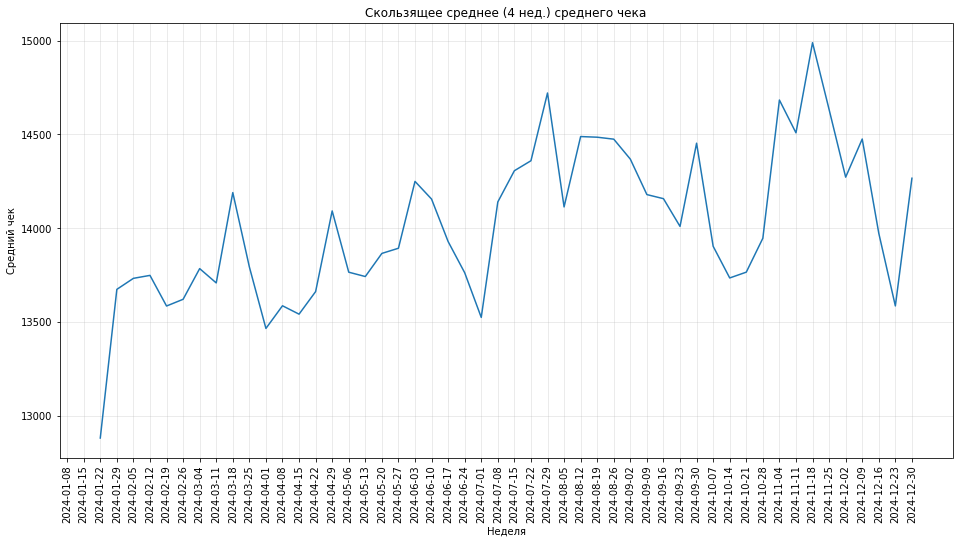

In [15]:
aov = pa_marketplace_orders.groupby('order_week')['total_price'].mean().reset_index()
aov['aov_rolling'] = aov['total_price'].rolling(window=4).mean()
plt.figure(figsize=(16, 8))
plt.plot(aov['order_week'], aov['aov_rolling'])
plt.xlabel("Неделя")
plt.ylabel("Средний чек")
plt.title("Скользящее среднее (4 нед.) среднего чека")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.show()

Средний чек не показывает негатвную динамику.

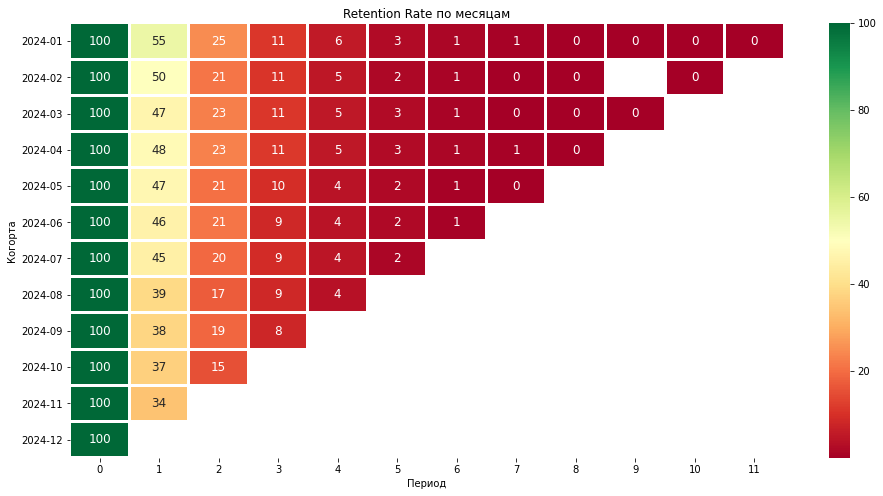

In [16]:
retention_df = pa_marketplace_events.copy()
retention_df['event_month_p'] = pd.to_datetime(retention_df['event_month']).dt.to_period('M')
retention_df['first_month'] = retention_df.groupby('user_id')['event_month_p'].transform('min')
retention_df['period'] = retention_df['event_month_p'].astype(int) - retention_df['first_month'].astype(int)
cohort_period_active = (
    retention_df
    .groupby(['first_month', 'period'])['user_id']
    .nunique()
    .reset_index()
)
df_pivot_retention = cohort_period_active.pivot(index='first_month', columns='period', values='user_id')
cohort_sizes = df_pivot_retention[0]
df_pivot_retention = df_pivot_retention.apply(lambda row: (row / cohort_sizes[row.name]) * 100, axis=1)

plt.figure(figsize=(16, 8))

sns.heatmap(df_pivot_retention,
           cmap='RdYlGn',
           annot=True,
           fmt='.0f',
           linewidths=2,
           annot_kws={"size": 12})

plt.title('Retention Rate по месяцам')
plt.xlabel('Период')
plt.ylabel('Когорта')
plt.show()

Retention rate снижается для всех когорт, особенно сильное падение для когорты августа.

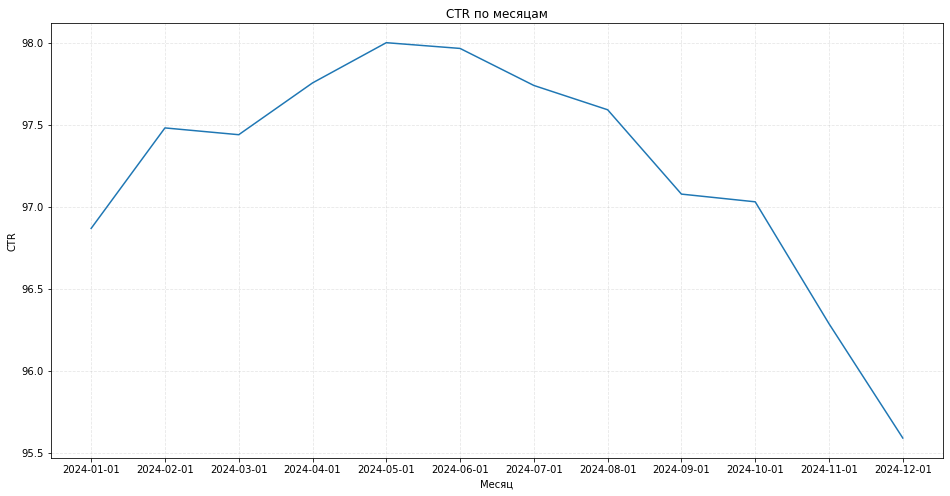

In [17]:
views_by_month = (
    pa_marketplace_events[pa_marketplace_events['event_type'] == 'product_view']
    .groupby('event_month')['event_id']
    .count()
    .rename('product_view')
)

clicks_by_month = (
    pa_marketplace_events[pa_marketplace_events['event_type'] == 'product_click']
    .groupby('event_month')['event_id']
    .count()
    .rename('product_click')
)

monthly_ctr = pd.concat([views_by_month, clicks_by_month], axis=1)
monthly_ctr['ctr'] = (monthly_ctr['product_click'] / monthly_ctr['product_view']) * 100
plt.figure(figsize=(16, 8))
plt.plot(monthly_ctr.index, monthly_ctr['ctr'])
plt.xlabel("Месяц")
plt.ylabel("CTR")
plt.title("CTR по месяцам")
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

CTR падает с июня.

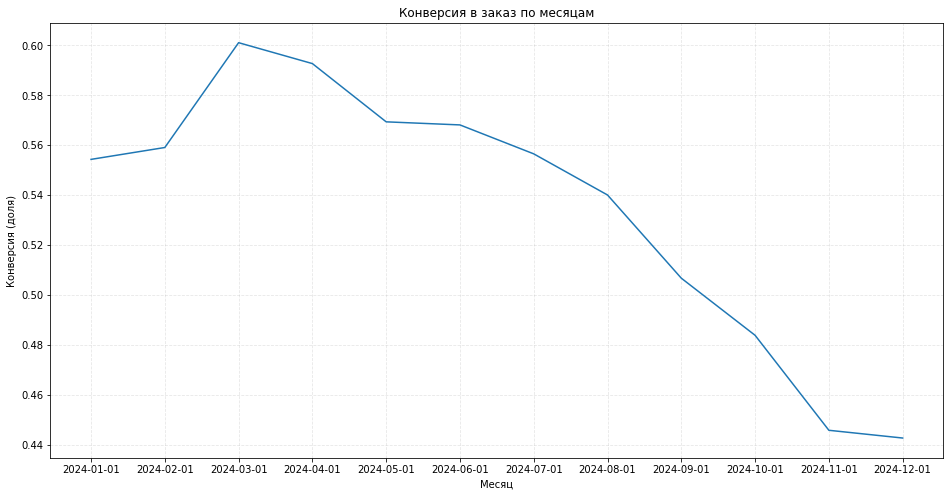

In [18]:
users_with_product_view = pa_marketplace_events[pa_marketplace_events['event_type'] == 'product_view'].groupby('event_month')['user_id'].nunique()
users_with_order = pa_marketplace_events[pa_marketplace_events['event_type'] == 'checkout_complete'].groupby('event_month')['user_id'].nunique()

cr_df = pd.concat([users_with_product_view, users_with_order], axis=1)
cr_df.columns = ['users_product_view', 'users_checkout_complete']

cr_df['conversion'] = cr_df['users_checkout_complete'] / cr_df['users_product_view']

plt.figure(figsize=(16, 8))
plt.plot(cr_df.index, cr_df['conversion'])
plt.title('Конверсия в заказ по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Конверсия (доля)')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

### 3. Оценка метрик монетизации и юнит-экономики

In [19]:
display(pa_marketplace_orders.head())

,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
0,1,3,2024-01-19 01:52:52,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
1,2,3,2024-01-19 01:52:52,Молоток слесарный,1,11340.38,11340.38,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
2,3,3,2024-01-19 01:52:52,Секатор садовый,2,10892.09,21784.18,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
3,4,3,2024-01-25 13:59:38,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-22,2024-01-01
4,5,3,2024-01-25 13:59:38,Чай черный,1,2099.59,2099.59,Продукты питания,2024-01-22,2024-01-01


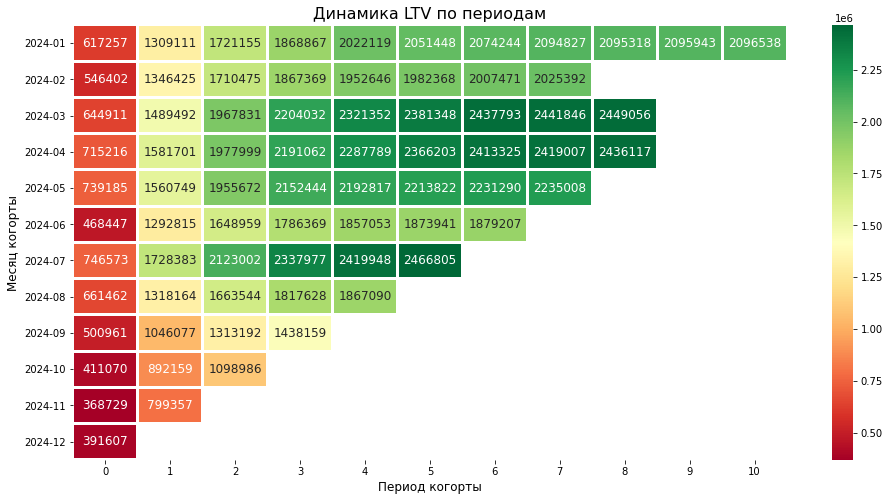

In [20]:
orders_with_cohort = pa_marketplace_orders.merge(pa_marketplace_users[['user_id', 'cohort_month']], on='user_id', how='left')
orders_with_cohort['revenue'] = orders_with_cohort['total_price'] * 0.05
orders_with_cohort['order_month'] = pd.to_datetime(orders_with_cohort['order_month']).dt.to_period('M')
orders_with_cohort['cohort_month'] = pd.to_datetime(orders_with_cohort['cohort_month']).dt.to_period('M')
orders_with_cohort['period'] = orders_with_cohort['order_month'].astype(int) - orders_with_cohort['cohort_month'].astype(int)


cohort_stats = (orders_with_cohort
    .groupby(['cohort_month', 'period'])['revenue']
    .sum()
    .groupby('cohort_month')
    .cumsum()
    .reset_index()
    .rename(columns={'revenue': 'cumulative_ltv'}))

df_pivot_ltv = cohort_stats.pivot(
    index='cohort_month', columns='period', values='cumulative_ltv')

plt.figure(figsize=(16, 8))
sns.heatmap(df_pivot_ltv,
           cmap='RdYlGn',
           annot=True,
           fmt='.0f',
           linewidths=2,
           annot_kws={"size": 12})

plt.title('Динамика LTV по периодам', fontsize=16)
plt.xlabel('Период когорты', fontsize=12)
plt.ylabel('Месяц когорты', fontsize=12)
plt.show()


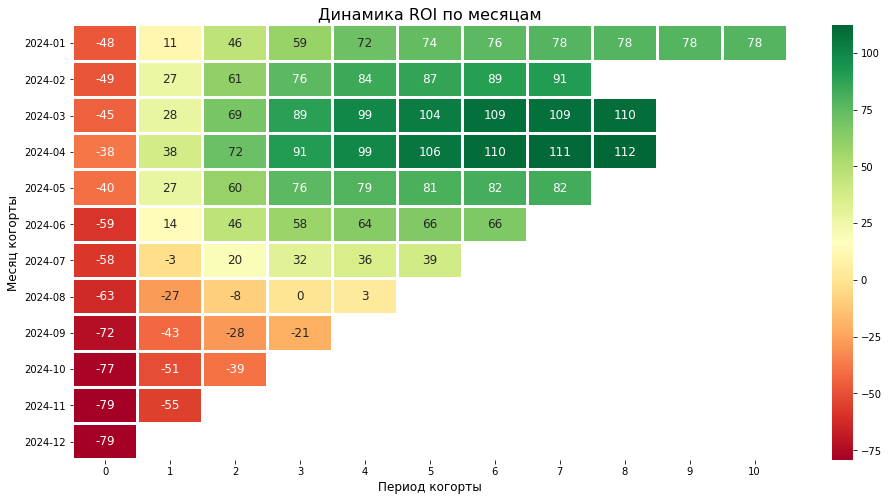

In [21]:
cohort_budget = pa_marketplace_campaign_costs.groupby('spend_month')['budget'].sum().reset_index().rename(columns={'spend_month': 'cohort_month'})
cohort_budget['cohort_month'] = pd.to_datetime(cohort_budget['cohort_month']).dt.to_period('M')
cohort_roi = cohort_stats.merge(cohort_budget, on='cohort_month', how='left')
cohort_roi['roi'] = (cohort_roi['cumulative_ltv'] / cohort_roi['budget'] - 1) * 100

df_pivot_roi = cohort_roi.pivot(
    index='cohort_month', columns='period', values='roi')

plt.figure(figsize=(16, 8))
sns.heatmap(df_pivot_roi,
           cmap='RdYlGn',
           annot=True,
           fmt='.0f',
           linewidths=2,
           annot_kws={"size": 12})

plt.title('Динамика ROI по месяцам', fontsize=16)
plt.xlabel('Период когорты', fontsize=12)
plt.ylabel('Месяц когорты', fontsize=12)
plt.show()

## Выводы по этапам 2 и 3


Начиная с августа-сентября 2024 года все ключевые показатели пошли вниз, и это не похоже на сезонность, а скорее на фундаментальную проблему. Продукт деградирует по основным показателям. Рост был только в первой половине года (январь-июнь). Сейчас виден спад.  

Тревожные сигналы:
- Резкое падение конверсии в заказ и ARPU во втором полугодии (продукт перестал монетизировать аудиторию).
- Критическое ухудшение удержания (новые пользователи уходят быстрее, чем полгода назад).
- Отрицательный ROI для когорт, привлеченных после июля (тратятся деньги на привлечение, которое не окупается).

## 4. Поиск инсайтов, точек роста и сегментация


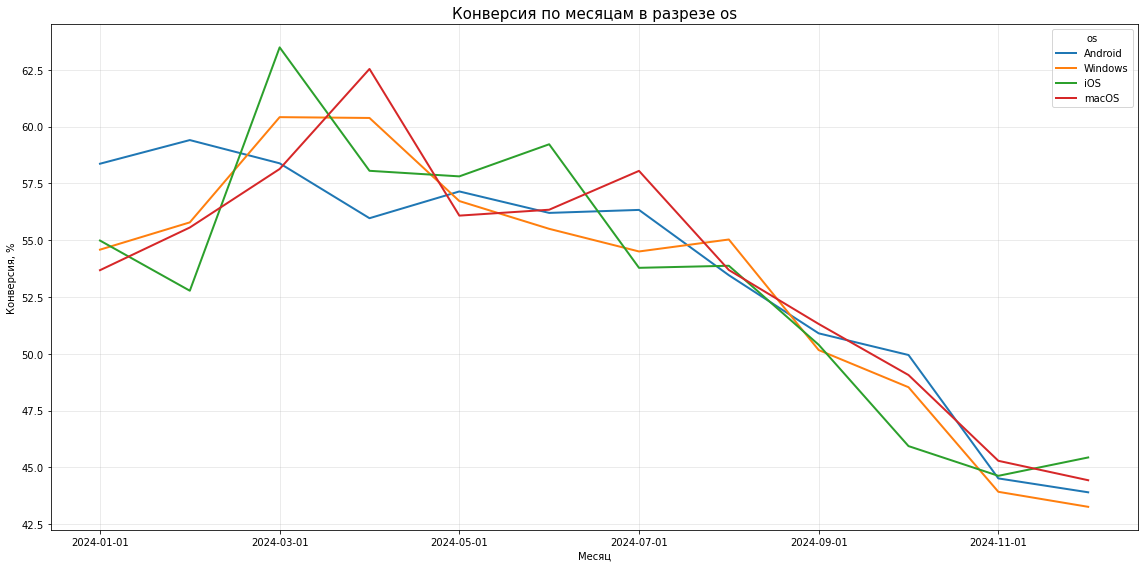

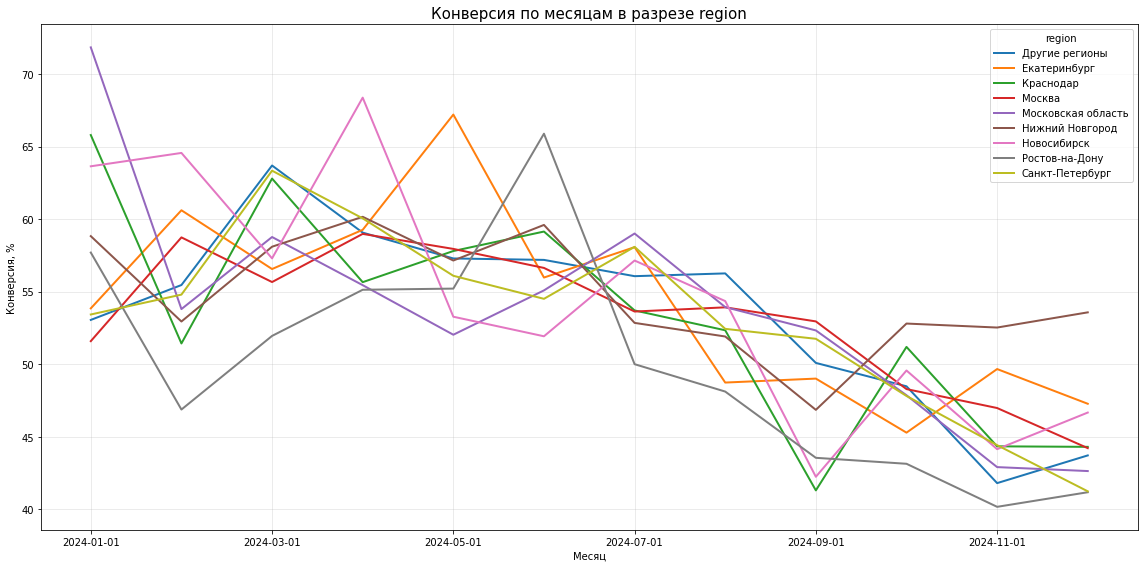

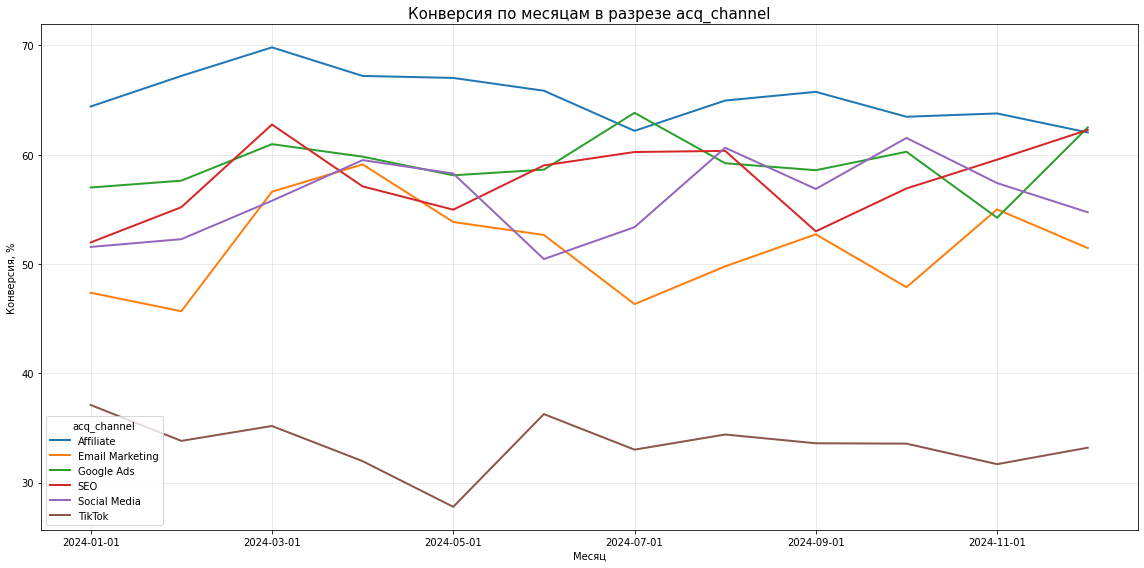

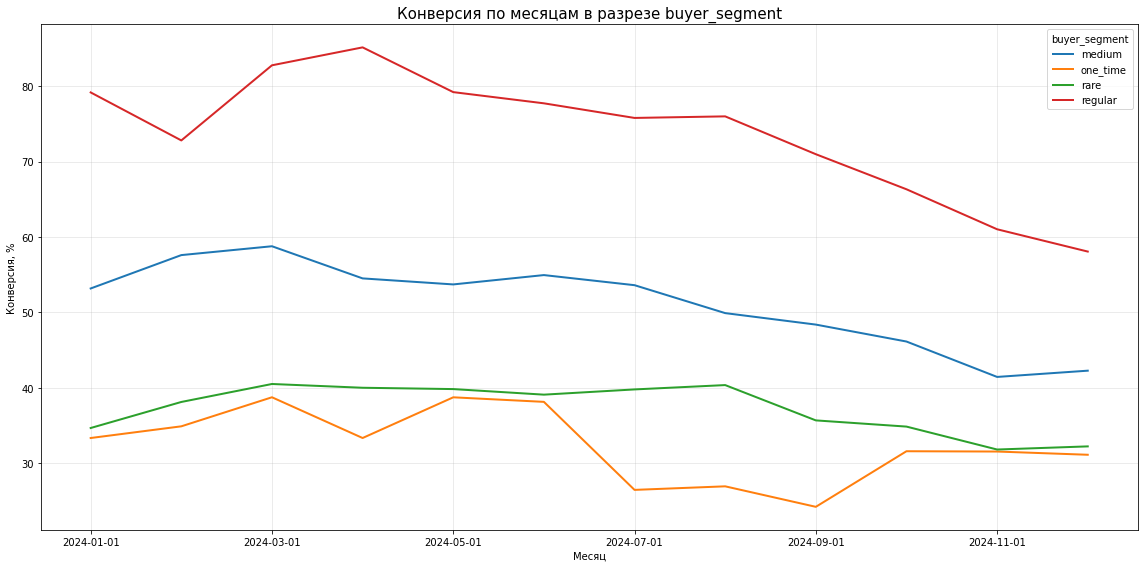

In [22]:
events_with_users = pa_marketplace_events.merge(pa_marketplace_users, on='user_id', how='left')
views_all = events_with_users[events_with_users['event_type'] == 'product_view']
orders_all = events_with_users[events_with_users['event_type'] == 'checkout_complete']
slices = ['os', 'region', 'acq_channel', 'buyer_segment']

for col in slices:
    
    views = (
        views_all
        .groupby(['event_month', col])['user_id']
        .nunique()
        .reset_index(name='views')
    )

    orders = (
        orders_all
        .groupby(['event_month', col])['user_id']
        .nunique()
        .reset_index(name='orders')
    )

    conversion = views.merge(orders, on=['event_month', col], how='left')
    conversion['orders'] = conversion['orders'].fillna(0)
    conversion = conversion[conversion['views'] > 0]
    conversion['conversion_pct'] = (conversion['orders'] / conversion['views']) * 100
    conversion = conversion.sort_values('event_month')

    conv_pivot = conversion.pivot(index='event_month', columns=col, values='conversion_pct')
    ax = conv_pivot.plot(figsize=(16, 8), linewidth=2, markersize=6)
    ax.set_xlabel("Месяц")
    ax.set_ylabel("Конверсия, %")
    ax.set_title(f"Конверсия по месяцам в разрезе {col}", fontsize=15)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [23]:
print(pa_marketplace_events['event_type'].unique())

['page_view' 'product_view' 'product_click' 'add_to_cart' 'checkout_start'
 'checkout_complete' 'user_logout' 'search' 'category_view' 'filter_apply'
 'promo_view' 'wishlist_add' 'user_login' 'banner_click'
 'remove_from_cart']


In [24]:
funnel_steps = ['page_view', 'product_view', 'product_click', 'add_to_cart', 'checkout_start', 'checkout_complete']
funnel_df_steps = pa_marketplace_events[pa_marketplace_events['event_type'].isin(funnel_steps)]
funnel_counts =  funnel_df_steps.groupby('event_type')['user_id'].nunique().reindex(funnel_steps)
funnel_df = pd.DataFrame({
   'step': funnel_counts.index,
   'users': funnel_counts.values
})
funnel_df['conversion_from_first_%'] = ((funnel_df['users'] / funnel_df['users'].loc[0]) * 100).round(1)
funnel_df['conversion_from_previous_%'] = (funnel_df['users'].div(funnel_df['users'].shift(1)) * 100).round(1)

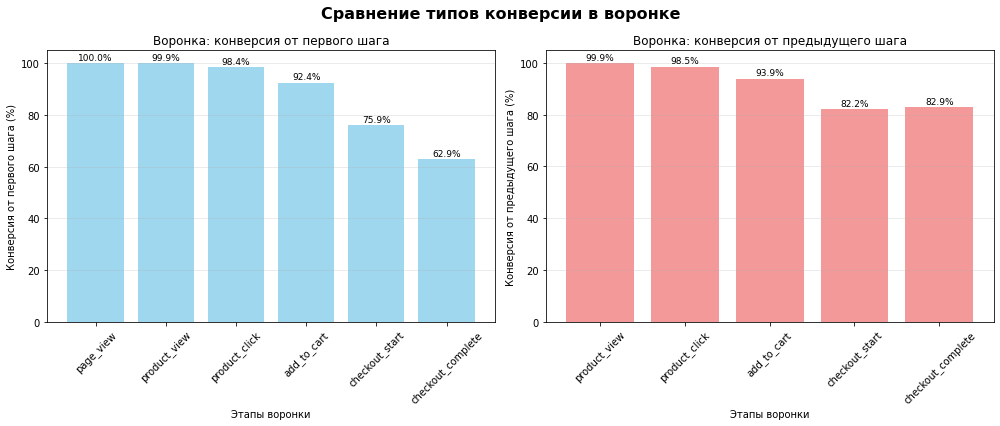

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

filtered_df = funnel_df.iloc[1:]

bars1 = ax1.bar(funnel_df['step'], funnel_df['conversion_from_first_%'], color='skyblue', alpha=0.8)
ax1.set_title('Воронка: конверсия от первого шага')
ax1.set_ylabel('Конверсия от первого шага (%)')
ax1.set_xlabel('Этапы воронки')
ax1.grid(axis='y', alpha=0.3)
ax1.tick_params(axis='x', labelrotation=45)
for bar, value in zip(bars1, funnel_df['conversion_from_first_%']):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f'{value}%',
        ha='center',
        va='bottom',
        fontsize=9,
        color='black'
    )

bars2 = ax2.bar(filtered_df['step'], filtered_df['conversion_from_previous_%'], color='lightcoral', alpha=0.8)
ax2.set_title('Воронка: конверсия от предыдущего шага')
ax2.set_ylabel('Конверсия от предыдущего шага (%)')
ax2.set_xlabel('Этапы воронки')
ax2.grid(axis='y', alpha=0.3)
ax2.tick_params(axis='x', labelrotation=45)
for bar, value in zip(bars2, filtered_df['conversion_from_previous_%']):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f'{value}%',
        ha='center',
        va='bottom',
        fontsize=9,
        color='black'
    )
plt.suptitle('Сравнение типов конверсии в воронке', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [26]:
orders_merged = pa_marketplace_orders.merge(
    pa_marketplace_users[['user_id', 'cohort_month', 'acq_channel', 'buyer_segment']], 
    on='user_id', 
    how='left'
)

orders_merged['revenue'] = orders_merged['total_price'] * 0.05

orders_merged['order_month'] = pd.to_datetime(orders_merged['order_month']).dt.to_period('M')
orders_merged['cohort_month'] = pd.to_datetime(orders_merged['cohort_month']).dt.to_period('M')
orders_merged['period'] = orders_merged['order_month'].astype(int) - orders_merged['cohort_month'].astype(int)

cohort_stats_detailed = (
    orders_merged
    .groupby(['cohort_month', 'period', 'acq_channel', 'buyer_segment'])['revenue']
    .sum()
    .groupby(['cohort_month', 'acq_channel', 'buyer_segment'])
    .cumsum()
    .reset_index()
    .rename(columns={'revenue': 'cumulative_ltv'})
)

cohort_budget_detailed = (
    pa_marketplace_campaign_costs
    .groupby(['spend_month', 'acq_channel'])['budget']
    .sum()
    .reset_index()
    .rename(columns={'spend_month': 'cohort_month'})
)
cohort_budget_detailed['cohort_month'] = pd.to_datetime(cohort_budget_detailed['cohort_month']).dt.to_period('M')

cohort_roi_detailed = cohort_stats_detailed.merge(
    cohort_budget_detailed, 
    on=['cohort_month', 'acq_channel'], 
    how='left'
)

cohort_roi_detailed['roi'] = ((cohort_roi_detailed['cumulative_ltv'] / cohort_roi_detailed['budget']) - 1) * 100

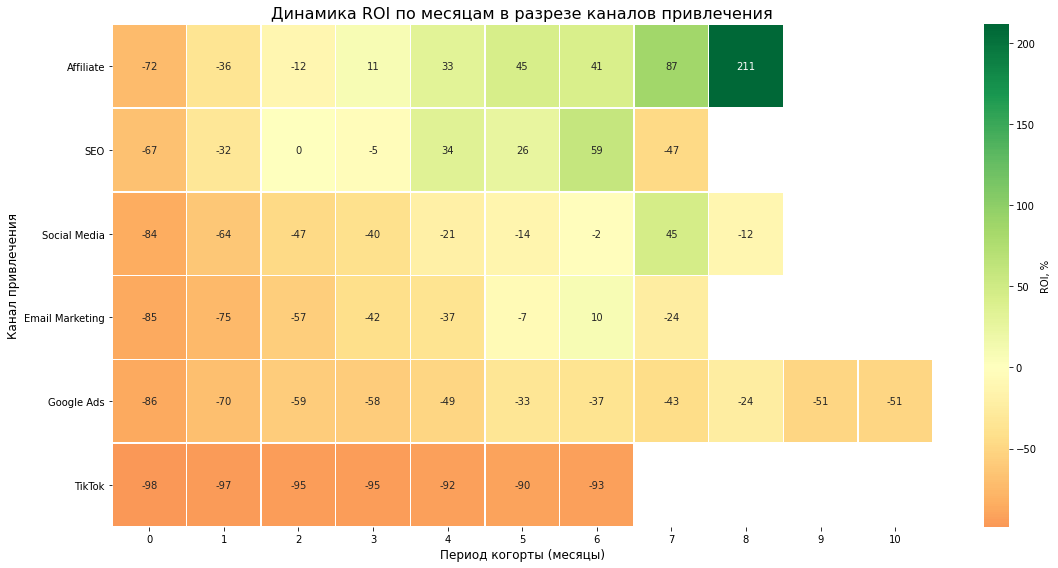

In [27]:
pivot_channel_period = cohort_roi_detailed.pivot_table(
    index='acq_channel', 
    columns='period', 
    values='roi', 
    aggfunc='mean'
)

pivot_channel_period = pivot_channel_period.reindex(
    pivot_channel_period.mean(axis=1).sort_values(ascending=False).index
)

plt.figure(figsize=(16, 8))
sns.heatmap(
    pivot_channel_period, 
    annot=True,          
    fmt='.0f',           
    cmap='RdYlGn',       
    center=0,            
    linewidths=0.5,
    cbar_kws={'label': 'ROI, %'} 
)

plt.title('Динамика ROI по месяцам в разрезе каналов привлечения', fontsize=16)
plt.xlabel('Период когорты (месяцы)', fontsize=12)
plt.ylabel('Канал привлечения', fontsize=12)
plt.tight_layout()
plt.show()

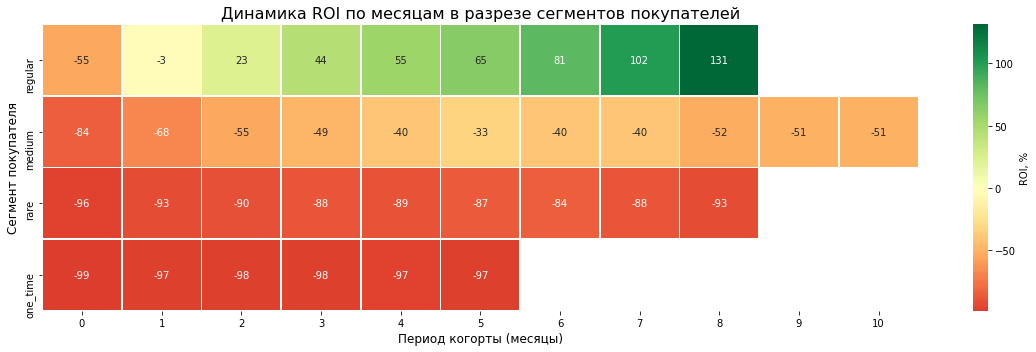

In [28]:
pivot_segment_period = cohort_roi_detailed.pivot_table(
    index='buyer_segment', 
    columns='period', 
    values='roi', 
    aggfunc='mean'
)

pivot_segment_period = pivot_segment_period.reindex(
    pivot_segment_period.mean(axis=1).sort_values(ascending=False).index
)

plt.figure(figsize=(16, 5))
sns.heatmap(
    pivot_segment_period, 
    annot=True,          
    fmt='.0f',           
    cmap='RdYlGn',       
    center=0,            
    linewidths=0.5,
    cbar_kws={'label': 'ROI, %'} 
)

plt.title('Динамика ROI по месяцам в разрезе сегментов покупателей', fontsize=16)
plt.xlabel('Период когорты (месяцы)', fontsize=12)
plt.ylabel('Сегмент покупателя', fontsize=12)
plt.tight_layout()
plt.show()

## Выводы по этапу 4

Проведя углубленный анализ предоставленных срезов, можно сделать однозначный вывод: падение во втором полугодии 2024 года носит не рыночный (сезонный), а системный характер. Оно равномерно охватило практически все каналы, регионы и ОС, но с разной степенью критичности. У продукта есть четкие «островки стабильности», которые вытягивали ситуацию в начале года, но сейчас и они сдают позиции. 

Динамика по сегментам покупателей: 
- Лучший сегмент `regular`. Его конверсия в заказ самая высокая (держалась выше 75% до осени, сейчас ~58%) и, что важнее, это единственный сегмент с положительным ROI. Когортный ROI у `regular` выходит в плюс к 3-му месяцу и достигает +131% к 8-му.

- Проблемные сегменты - `one_time` и `rare`. Конверсия находится на уровне 25-35%. Более того, их ROI остается отрицательным на протяжении всего жизненного цикла.

- Гипотеза: «Если перевести фокус маркетинговых активностей с привлечения "новых/разовых" клиентов на удержание и активацию "регулярных", мы сможем сохранить доходность на фоне общего падения рынка». Основание: Только сегмент `regular` выходит на окупаемость, в то время как остальные сегменты тянут бюджет в минус.

Эффективность каналов привлечения:
- Эффективные каналы Affiliate и SEO. У них самая высокая и стабильная конверсия (62-65%). По ROI они также выходят в уверенный плюс, особенно партнерская сеть (до +211% к 9-му месяцу).
- Неэффективные канал - TikTok, Google Ads и Email-маркетинг. Для TikTok конверсия держится на уровне 30-35%, а ROI стабильно колеблется около -90% на протяжении всего срока наблюдения. Это систематическое сжигание бюджета. Google Ads и Email-маркетинг также глубоко убыточны.

- Гипотеза: «Если полностью остановить закупку в TikTok и перераспределить освободившийся бюджет на масштабирование партнерской сети и SEO, мы снизим убытки без потери целевого качественного трафика».

Воронка продаж:
- Анализ воронки отвечает на вопрос, почему общая конверсия упала с 0,60 до 0,44. Ключевая дыра в воронке находится на этапе «переход из корзины в оформление заказа» и непосредственно «процесс оплаты». От общего потока посетителей каждый третий (37,1%) кладет товар в корзину, но так и не оплачивает его.
- Гипотеза: «Если внедрить механизм бесплатной доставки при достижении определенной суммы корзины и показывать пользователю прогресс-бар с суммой до бесплатной доставки, то количество переходов из корзины в оформление заказа увеличится.»



<div class="alert alert-success">
<b>👍 Успех:</b> Молодец, построены все нужные воронки!

Воронки действительно можно строить в виде столбчатых графиков и таблиц, но есть способ строить именно воронки с автоматическим расчетом перехода как от первого шага, так и от предыдущего, примеры построения таких воронок можно посмотреть здесь

- https://habr.com/ru/companies/otus/articles/588190/

Молодец, что и здесь отмечаешь проблемы с TikTok, много пользователей отваливается после регистрации, это одно из самых слабых мест. Можно взять только канал TikTok и посмотреть на сегментацию по нему, чтобы определить те сегменты, на которое идет максимальный эффект по этому каналу.

Так же хорошая рекомендация поработать с категориями и аудиторией каналов, не всегда стоит просто отключать слабый канал - иногда имеет смысл поработать с аудиторией, изменить оффер, применить бонусы, чтобы попытаться вовлечь этих пользователей. Только если это не сработает, можно будет говорить о перераспределении бюджета в пользу других источников.

Падение метрик Gogole Ads связано в прекращением его деятельности в РФ
</div>

## 5. Подготовка эксперимента и подведение его результатов

In [29]:
pa_marketplace_events_AB = pd.read_csv('/datasets/pa_marketplace_events_AB.csv')
pa_marketplace_orders_AB = pd.read_csv('/datasets/pa_marketplace_orders_AB.csv')
pa_marketplace_users_AB = pd.read_csv('/datasets/pa_marketplace_users_AB.csv')
pa_marketplace_AB_split_users = pd.read_csv('/datasets/pa_marketplace_AB_split_users.csv')

In [30]:
user_groups_count = pa_marketplace_AB_split_users.groupby('user_id')['group'].nunique()
users_in_multiple_groups = user_groups_count[user_groups_count > 1]
if len(users_in_multiple_groups) == 0:
    print("Все пользователи назначены ровно в одну группу")
else:
    print(f"Найдено {len(users_in_multiple_groups)} пользователей в нескольких группах:")
    problematic_users = pa_marketplace_AB_split_users[
        pa_marketplace_AB_split_users['user_id'].isin(users_in_multiple_groups.index)
    ].sort_values('user_id')
    display(problematic_users)

Все пользователи назначены ровно в одну группу


In [31]:
c, t = pa_marketplace_AB_split_users.groupby('group')['user_id'].nunique()
print(f"Control: {c}, Treatment: {t}, Разница: {abs(c-t)} ({abs(c-t)/(c+t)*100:.2f}%)")

Control: 1503, Treatment: 1465, Разница: 38 (1.28%)


In [32]:
events_ab = pa_marketplace_events_AB.merge(pa_marketplace_AB_split_users[['user_id', 'group']], on='user_id', how='inner')
print(f"Уникальных пользователей: {events_ab['user_id'].nunique()}")

Уникальных пользователей: 499


In [33]:
orders_ab = pa_marketplace_orders_AB.merge(pa_marketplace_AB_split_users[['user_id', 'group']], on='user_id', how='inner')
print(f"Уникальных пользователей: {orders_ab['user_id'].nunique()}")

Уникальных пользователей: 126


В events_ab и orders_ab оставляем только пользователей, попавших в AB-тест.

In [34]:
users = events_ab[['user_id', 'group']].drop_duplicates()

orders_ab['revenue'] = orders_ab['total_price'] * 0.05

user_revenue = orders_ab.groupby('user_id')['revenue'].sum().reset_index()
user_revenue.columns = ['user_id', 'total_revenue']

user_metrics = users.merge(user_revenue, on='user_id', how='left')
user_metrics['total_revenue'] = user_metrics['total_revenue'].fillna(0)

control_group = user_metrics[user_metrics['group'] == 'control']
treatment_group = user_metrics[user_metrics['group'] == 'treatment']

In [35]:
users_control = control_group['user_id'].nunique()
buyers_control = control_group[control_group['total_revenue'] > 0]['user_id'].nunique()
users_treatment = treatment_group['user_id'].nunique()
buyers_treatment = treatment_group[treatment_group['total_revenue'] > 0]['user_id'].nunique()

arpu_control = control_group['total_revenue'].mean()
arpu_treatment = treatment_group['total_revenue'].mean()

arppu_control = control_group[control_group['total_revenue'] > 0]['total_revenue'].mean()
arppu_treatment = treatment_group[treatment_group['total_revenue'] > 0]['total_revenue'].mean()

conv_control = buyers_control / users_control
conv_treatment = buyers_treatment / users_treatment

aov_control = orders_ab[orders_ab['group'] == 'control']['total_price'].mean()
aov_treatment = orders_ab[orders_ab['group'] == 'treatment']['total_price'].mean()

revenue_control = control_group[control_group['total_revenue'] > 0]['total_revenue'].sum()
revenue_treatment = treatment_group[treatment_group['total_revenue'] > 0]['total_revenue'].sum()

Нулевая гипотеза: бонус не повлиял на конверсию в покупку.  
Альтернативная гипотеза: бонус повлиял на конверсию в покупку, конверсия в контрольной группе меньше чем в тестовой.

In [45]:
count = np.array([buyers_control, buyers_treatment])
nobs = np.array([users_control, users_treatment])
z_stat_conv, p_value_conv = proportions_ztest(count, nobs, alternative='smaller')

print(" КОНВЕРСИЯ:")
print(f"  Control:    {conv_control:.2%}  ({buyers_control}/{users_control})")
print(f"  Treatment:  {conv_treatment:.2%}  ({buyers_treatment}/{users_treatment})")
print(f"  Разница:    {conv_treatment - conv_control:+.2%}")
print(f"  Лифт:       {(conv_treatment/conv_control - 1)*100:+.1f}%")
print(f"  p-value:    {p_value_conv:.4f}")
print(f"  Резултат:    {'✅ Отвергаем нулевую гипотезу в пользу альтернативной' if p_value_conv < 0.05 else '❌ Отвергаем альтернативную гипотезу в пользу нулевой'}")

 КОНВЕРСИЯ:
  Control:    2.30%  (6/261)
  Treatment:  18.07%  (43/238)
  Разница:    +15.77%
  Лифт:       +685.9%
  p-value:    0.0000
  Резултат:    ✅ Отвергаем нулевую гипотезу в пользу альтернативной


Изменения в конверсии в покупку статистически значимы.

Нулевая гипотеза: бонус не повлиял на метрику ARPU.  
Альтернативная гипотеза: бонус повлиял на ARPU, значения метрики в контрольной группе меньше.

In [37]:
t_stat_arpu, p_value_arpu = ttest_ind(control_group['total_revenue'],treatment_group['total_revenue'],equal_var=False,alternative='less')

print(" ARPU (средняя выручка на ВСЕХ пользователей):")
print(f"  Control:    {arpu_control:.2f}")
print(f"  Treatment:  {arpu_treatment:.2f}")
print(f"  Разница:    {arpu_treatment - arpu_control:+.2f}")
print(f"  Лифт:       {(arpu_treatment/arpu_control - 1)*100:+.1f}%")
print(f"  t-статистика: {t_stat_arpu:.4f}")
print(f"  p-value:    {p_value_arpu:.4f}")
print(f"  Резултат:    {'✅ Отвергаем нулевую гипотезу в пользу альтернативной' if p_value_arpu < 0.05 else '❌ Отвергаем альтернативную гипотезу в пользу нулевой'}")

 ARPU (средняя выручка на ВСЕХ пользователей):
  Control:    23.39
  Treatment:  276.95
  Разница:    +253.56
  Лифт:       +1084.2%
  t-статистика: -3.7551
  p-value:    0.0001
  Резултат:    ✅ Отвергаем нулевую гипотезу в пользу альтернативной


Рост средней выручки на пользователя в тестовой группе статистически значим.

Нулевая гипотеза: бонус не повлиял на метрику ARPPU.  
Альтернативная гипотеза: бонус повлиял на ARPPU, значения метрики в контрольной группе меньше.

In [47]:
control_buyers_data = control_group[control_group['total_revenue'] > 0]['total_revenue']
treatment_buyers_data = treatment_group[treatment_group['total_revenue'] > 0]['total_revenue']

t_stat_arppu, p_value_arppu = ttest_ind(control_buyers_data,treatment_buyers_data,equal_var=False,alternative='less')

print(" ARPPU (средняя выручка на ПОКУПАТЕЛЯ):")
print(f"  Control:    {arppu_control:.2f}  (n={len(control_buyers_data)})")
print(f"  Treatment:  {arppu_treatment:.2f}  (n={len(treatment_buyers_data)})")
print(f"  Разница:    {arppu_treatment - arppu_control:+.2f}")
print(f"  Лифт:       {(arppu_treatment/arppu_control - 1)*100:+.1f}%")
print(f"  t-статистика: {t_stat_arppu:.4f}")
print(f"  p-value:    {p_value_arppu:.4f}")
print(f"  Резултат:    {'✅ Отвергаем нулевую гипотезу в пользу альтернативной' if p_value_arppu < 0.05 else '❌ Отвергаем альтернативную гипотезу в пользу нулевой'}")

 ARPPU (средняя выручка на ПОКУПАТЕЛЯ):
  Control:    1017.38  (n=6)
  Treatment:  1532.89  (n=43)
  Разница:    +515.50
  Лифт:       +50.7%
  t-статистика: -1.3761
  p-value:    0.0895
  Резултат:    ❌ Отвергаем альтернативную гипотезу в пользу нулевой


Рост средней выручки на платящего пользователя в тестовой группе статистически не значим.

Нулевая гипотеза: бонус не повлиял на метрику AOV.  
Альтернативная гипотеза: бонус повлиял на AOV, значения метрики в тестовой группе меньше.

In [39]:
orders_control = orders_ab[orders_ab['group'] == 'control']['total_price']
orders_treatment = orders_ab[orders_ab['group'] == 'treatment']['total_price']

t_stat_aov, p_value_aov = ttest_ind(orders_control,orders_treatment,equal_var=False,alternative='less')

print(" AOV (средний чек на один заказ):")
print(f"  Control:    {aov_control:.2f}  (n={len(orders_control)})")
print(f"  Treatment:  {aov_treatment:.2f}  (n={len(orders_treatment)})")
print(f"  Разница:    {aov_treatment - aov_control:+.2f}")
print(f"  Лифт:       {(aov_treatment/aov_control - 1)*100:+.1f}%")
print(f"  t-статистика: {t_stat_aov:.4f}")
print(f"  p-value:    {p_value_aov:.4f}")
print(f"  Резултат:    {'✅ Отвергаем нулевую гипотезу в пользу альтернативной' if p_value_aov < 0.05 else '❌ Отвергаем альтернативную гипотезу в пользу нулевой'}")

 AOV (средний чек на один заказ):
  Control:    15765.54  (n=24)
  Treatment:  16647.61  (n=231)
  Разница:    +882.07
  Лифт:       +5.6%
  t-статистика: -0.2719
  p-value:    0.3936
  Резултат:    ❌ Отвергаем альтернативную гипотезу в пользу нулевой


Бонус не повлиял на средний чек.

In [41]:
print(" Суммарная выручка:")
print(f"  Control:    {revenue_control:.2f}")
print(f"  Treatment:  {revenue_treatment:.2f}")
print(f"  Разница:    {revenue_treatment - revenue_control:+.2f}")
print(f"  Лифт:       {(revenue_treatment/revenue_control - 1)*100:+.1f}%")

 Суммарная выручка:
  Control:    6104.29
  Treatment:  65914.15
  Разница:    +59809.86
  Лифт:       +979.8%


In [48]:
print("Покупатели контрольной группы (orders_ab):", 
      orders_ab[orders_ab['group'] == 'control']['user_id'].nunique())
print("Покупатели тестовой группы (orders_ab):", 
      orders_ab[orders_ab['group'] == 'treatment']['user_id'].nunique())

Покупатели контрольной группы (orders_ab): 16
Покупатели тестовой группы (orders_ab): 110


Выбор суммарной выручки в качестве барьерной метрики не корректен. Метрика отражает финансовый показатель на текущий момент, а не здоровье продукта. Конкретно в нашем случае сравнивать выручку для 16 пользователей в контрольной и 110 в тестовой группах не имеет практического смысла. Предлагается в качестве барьерной метрики использовать ARPPU (среднюю выручку на платящего пользователя) или AOV (средний чек).

## Выводы по этапу 5

Мы зафиксировали позитивный сигнал по ключевым метрикам:

- Конверсия в покупку выросла с 2,3% до 18,07%
- ARPPU и средний чек статистически значимо не различаются между группами (это хорошо — мы не просели по деньгам на платящего пользователя).

Однако на данном этапе мы не можем принять финальное data-driven решение, потому что абсолютное число покупок в группах слишком мало (6 и 43). При такой базе даже небольшие колебания поведения пользователей дают многократное изменение конверсии, что делает результат неустойчивым и потенциально ложноположительным.  

Тест проводился в течение фиксированных 3 недель, набранного объема недостаточно для статистически устойчивых выводов.
На данный момент результат выглядит обнадеживающе, но требует подтверждения на большей выборке. Решение можно принимать только как экспертное, с осознанием риска.